# **Assignment 2: Training and Evaluation Practices**
*Group 3: Barry Zhang, Maeve Côté, Nicholas Belev*

## Importing Data, Libraries, and Setup

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
RANDOM_SEED = 2026 # Ensuring reproducible results with the train-test split
rng = np.random.default_rng(RANDOM_SEED) # Ensuring reproducible results with permutations / batch shuffling

**Automating the importing of Spambase Data directly into our local folder**

In [ ]:
target_dir = "sample_data" # We move the data into local sample_data folder
os.makedirs(target_dir, exist_ok=True)

file_path = os.path.join(target_dir, "spambase.data")

if not os.path.exists(file_path):
    # Download spambase.data directly from the URL
    !wget --no-check-certificate -N -P {target_dir} \
        "https://archive.ics.uci.edu/ml/machine-learning-databases/spambase/spambase.data"

# Labeling our columns since the data is a fully numeric CSV
feature_names = [
    "word_freq_make", "word_freq_address", "word_freq_all", "word_freq_3d",
    "word_freq_our", "word_freq_over", "word_freq_remove", "word_freq_internet",
    "word_freq_order", "word_freq_mail", "word_freq_receive", "word_freq_will",
    "word_freq_people", "word_freq_report", "word_freq_addresses",
    "word_freq_free", "word_freq_business", "word_freq_email", "word_freq_you",
    "word_freq_credit", "word_freq_your", "word_freq_font", "word_freq_000",
    "word_freq_money", "word_freq_hp", "word_freq_hpl", "word_freq_george",
    "word_freq_650", "word_freq_lab", "word_freq_labs", "word_freq_telnet",
    "word_freq_857", "word_freq_data", "word_freq_415", "word_freq_85",
    "word_freq_technology", "word_freq_1999", "word_freq_parts", "word_freq_pm",
    "word_freq_direct", "word_freq_cs", "word_freq_meeting",
    "word_freq_original", "word_freq_project", "word_freq_re",
    "word_freq_edu", "word_freq_table", "word_freq_conference",
    "char_freq_;", "char_freq_(", "char_freq_[", "char_freq_!",
    "char_freq_$", "char_freq_#", "capital_run_length_average",
    "capital_run_length_longest", "capital_run_length_total",
    "Class"
]

--2026-02-22 00:51:52--  https://archive.ics.uci.edu/ml/machine-learning-databases/spambase/spambase.data
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
  Issued certificate has expired.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘sample_data/spambase.data’

spambase.data           [ <=>                ] 686.47K  --.-KB/s    in 0.1s    

Last-modified header missing -- time-stamps turned off.
2026-02-22 00:51:52 (4.86 MB/s) - ‘sample_data/spambase.data’ saved [702942]



In [ ]:
df = pd.read_csv(file_path, header=None, names=feature_names)

# Keep X as a DataFrame for inspection
X = df.drop(columns=["Class"])
y = df["Class"].values


print(f"There are {X.shape[1]} features and {len(df)} samples in this dataset.\n")

# Convert X to NumPy only when we're done inspecting
X = X.values

print("\nData types and non-null counts:")
df.info()

There are 57 features and 4601 samples in this dataset.


Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4601 entries, 0 to 4600
Data columns (total 58 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   word_freq_make              4601 non-null   float64
 1   word_freq_address           4601 non-null   float64
 2   word_freq_all               4601 non-null   float64
 3   word_freq_3d                4601 non-null   float64
 4   word_freq_our               4601 non-null   float64
 5   word_freq_over              4601 non-null   float64
 6   word_freq_remove            4601 non-null   float64
 7   word_freq_internet          4601 non-null   float64
 8   word_freq_order             4601 non-null   float64
 9   word_freq_mail              4601 non-null   float64
 10  word_freq_receive           4601 non-null   float64
 11  word_freq_will              4601 non-null   float64
 12  

## Task 1 - Logistic Regression via Stochastic Gradient Descent (SGD)

In [ ]:
# 5% train, 95% test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=0.05,
    stratify=y, # Maintain the population ratio of Spam : Not Spam
    random_state=RANDOM_SEED # for reproducibility
)

print("Training samples:", X_train.shape[0])
print("Test samples:", X_test.shape[0])

# Pre-processing: standardization / normalization of all features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Training samples: 230
Test samples: 4371


**Implementing the Methods required for Logistic Regression** (from scratch)

In [ ]:
# Maps a linear score (w^T x + b) to a probability for Class = 1 (Spam)
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# The loss function: how well predicted probabilities match true labels
# Strongly penalizes high-confidence AND wrong answers
def binary_cross_entropy(y, y_hat):
    eps = 1e-8 # Numerical safety margin for predicted values "close enough" to 0 or 1
    y_hat = np.clip(y_hat, eps, 1 - eps)  # Since the sigmoid function can never reach asymptotes: P = 0 or P = 1
    return -np.mean(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))

# Classification accuracy given predicted probabilities
def accuracy(y_true, y_hat, threshold=0.5):
    y_pred = (y_hat >= threshold).astype(int)
    return np.mean(y_pred == y_true)

**Implementing Mini Batch SGD** (with L2 Regularization)

In [ ]:
def train_logistic_regression_sgd(
    X_train,
    y_train,
    learning_rate,
    batch_size,
    epochs,
    l2_lambda=0.0
):
    """
    Train logistic regression using mini-batch SGD.
    Returns learned weights, bias, and training loss & accuracies per epoch.
    """

    n_samples, n_features = X_train.shape

    # Initialize parameters
    w = np.zeros(n_features)
    b = 0.0

    losses = []
    accuracies = []

    for epoch in range(epochs):

        # Shuffle training data each epoch (reproducible via rng)
        indices = rng.permutation(n_samples)
        X_shuffled = X_train[indices]
        y_shuffled = y_train[indices]

        # Mini-batch loop
        for start in range(0, n_samples, batch_size):
            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            # Forward pass
            z = X_batch @ w + b
            y_hat = sigmoid(z)

            # Gradients of cross-entropy loss
            error = y_hat - y_batch
            grad_w = (X_batch.T @ error) / len(y_batch)
            grad_b = np.mean(error)

            # L2 regularization (exclude bias)
            grad_w += 2 * l2_lambda * w

            # Parameter update
            w -= learning_rate * grad_w
            b -= learning_rate * grad_b

        # Track training loss and accuracy after each epoch
        z_full = X_train @ w + b
        y_hat_full = sigmoid(z_full)

        loss = binary_cross_entropy(y_train, y_hat_full) + l2_lambda * np.sum(w ** 2)
        acc = accuracy(y_train, y_hat_full)

        losses.append(loss)
        accuracies.append(acc)

    return w, b, losses, accuracies

**L2 Regularization Convention**

In this training implementation, L2 regularization excludes the bias term from the penalty.  The regularized loss consists of the original logistic regression loss plus an L2 penalty applied only to the weight vector `w`.

This choice implies an additional gradient term proportional to the weights, specifically of the form `2 * lambda * w`, while the bias gradient is unchanged.

In code, this corresponds to: `grad_w += 2 * l2_lambda * w`

**This implementation uses the convention** where the regularization term is **`lambda * ||w||^2`**.
By rules of differentiation, the gradient contribution is thus `2 * lambda * w`.

The alternative convention: `(lambda / 2) * ||w||^2`, which would instead yield a gradient term of `lambda * w`, is *NOT* used.


**Testing the Logistic Regression**

In [ ]:
EPOCHS = 100 # Intuition: middleground between 50 and 200
LR = 0.01 # Learning rate, Intuition: 1*10^-2 is fast enough to make progress without diverging (hopefully)
BATCH_SIZE = 16 # # To compute gradient update, we pick a middleground between 1 and 64 observations

# No regularization
w_nr, b_nr, loss_nr, acc_nr = train_logistic_regression_sgd(
    X_train, y_train,
    learning_rate=LR,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    l2_lambda=0.0
)

# L2 regularization
w_l2, b_l2, loss_l2, acc_l2 = train_logistic_regression_sgd(
    X_train, y_train,
    learning_rate=LR,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    l2_lambda=1e-3
)

**Visualizing the Training Loss trend over each Epoch**

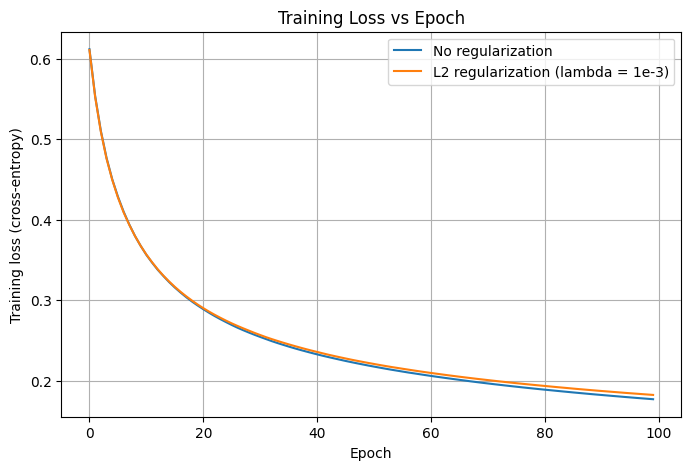

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(loss_nr, label="No regularization")
plt.plot(loss_l2, label="L2 regularization (lambda = 1e-3)")

plt.xlabel("Epoch")
plt.ylabel("Training loss (cross-entropy)")
plt.title("Training Loss vs Epoch")
plt.legend()
plt.grid(True)

plt.show()

The training cross-entropy loss decreases steadily over epochs for both models, with a rapid initial drop followed by slower convergence, consistent with stable SGD optimization. The non-regularized model begins to achieve marginally lower training loss after approximately 40 epochs, although the final difference by epoch 100 remains small (`< 0.01`). This behavior is expected, as L2 regularization constrains weight magnitudes and therefore trades slightly higher training loss for lower weights, reduced variance, and better model generalizability.

**Supplementary Task 1 Analysis: Accuracy**

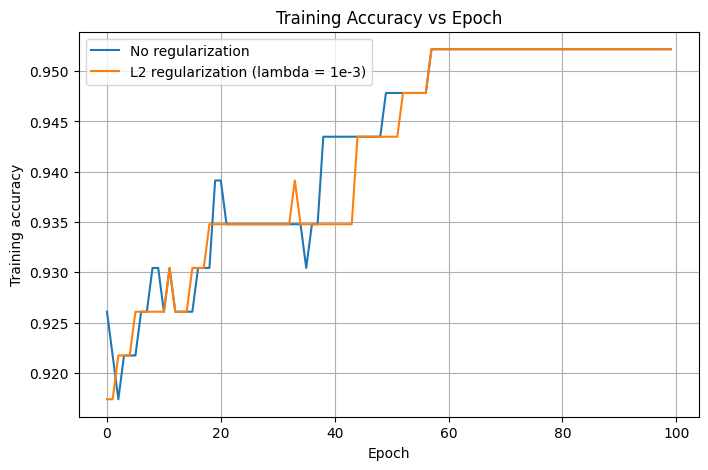

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(acc_nr, label="No regularization")
plt.plot(acc_l2, label="L2 regularization (lambda = 1e-3)")

plt.xlabel("Epoch")
plt.ylabel("Training accuracy")
plt.title("Training Accuracy vs Epoch")
plt.legend()
plt.grid(True)

plt.show()

In addition to training loss, we track training accuracy per epoch to provide an auxiliary view of optimization progress. Both the L2-regularized and non-regularized models achieve high training accuracy very early in training, exceeding 92% within the first few epochs and surpassing 95% by epoch 60 / 100. This indicates that the decision boundary is quickly placed in a region that separates the training data well, even while the loss continues to decrease more gradually.

**Supplementary Task 1 Analysis: Batch Size Comparison**

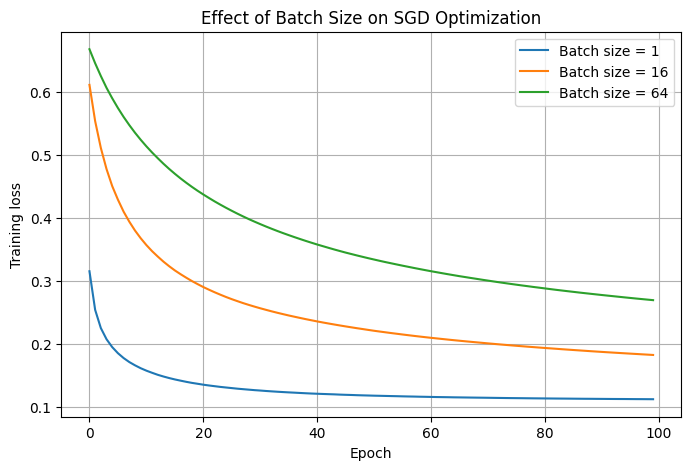

In [ ]:
batch_sizes = [1, 16, 64]
loss_curves = {}

for B in batch_sizes:
    _, _, losses, _ = train_logistic_regression_sgd(
        X_train,
        y_train,
        learning_rate=LR,
        batch_size=B,
        epochs=EPOCHS,
        l2_lambda=1e-3
    )
    loss_curves[B] = losses

plt.figure(figsize=(8, 5))
for B, losses in loss_curves.items():
    plt.plot(losses, label=f"Batch size = {B}")

plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Effect of Batch Size on SGD Optimization")
plt.legend()
plt.grid(True)
plt.show()

Using smaller batch sizes results in noisier but more frequent parameter updates. With batch size 1, the model performs many high-variance updates per epoch, allowing it to aggressively minimize training loss and potentially overfit the small training set. Larger batch sizes produce smoother and more conservative updates, which reduces variance but slows the rate at which training loss decreases.

This explains why batch size 1 achieves the lowest training loss (and the steepest relative decrease), followed respectively by batch sizes 16, then 64.

## Task 2 - Hyperparameter Tuning with K-Fold Cross-Validation

**Defining the Hyperparameter Values and Splitting Data into K-Folds**

In [ ]:
from sklearn.model_selection import KFold

# Hyperparameter grid
learning_rates = [1e-1, 1e-2, 1e-3, 1e-4]
batch_sizes = [1, 16, 32, 64, 128]
epoch_options = [50, 100, 150, 200]
# Note: 4 * 5 * 4 = 80 combinations in total to try

K = 5
kf = KFold(n_splits=K, shuffle=True, random_state=RANDOM_SEED)

cv_results = []

**Training, Testing, and Hyperparameter Tuning:** For each hyperparameter combination, run all K cross-validations (K-1 Training chunks, 1 Test chunk) by configuring the appropriate Logistic Regression -- and track performance metrics (mean and standard deviation for both loss and accuracy).

In [ ]:
# Triple loop to capture and evaluate all 80 combinations of hyperparameters

# w/ K = 5, this cell runs for 1 min
for lr in learning_rates:
    for B in batch_sizes:
        for epochs in epoch_options:

            fold_losses = []
            fold_accuracies = []

            # Looping through all folds in the K-fold
            for train_idx, val_idx in kf.split(X_train):

                # Split into CV train / validation folds
                X_tr, X_val = X_train[train_idx], X_train[val_idx]
                y_tr, y_val = y_train[train_idx], y_train[val_idx]

                # Train model on K-1 folds
                w, b, _, _ = train_logistic_regression_sgd(
                    X_tr,
                    y_tr,
                    learning_rate=lr,
                    batch_size=B,
                    epochs=epochs,
                    l2_lambda=1e-3  # fixed for Task 2
                )

                # Evaluate on held-out fold
                z_val = X_val @ w + b
                y_hat_val = sigmoid(z_val)

                val_loss = binary_cross_entropy(y_val, y_hat_val)
                val_acc = accuracy(y_val, y_hat_val)

                fold_losses.append(val_loss)
                fold_accuracies.append(val_acc)

            # Aggregate cross-validation results across folds
            cv_results.append({
                "learning_rate": lr,
                "batch_size": B,
                "epochs": epochs,
                "mean_cv_loss": np.mean(fold_losses),
                "std_cv_loss": np.std(fold_losses),
                "mean_cv_accuracy": np.mean(fold_accuracies),
                "std_cv_accuracy": np.std(fold_accuracies)
            })

Extra: the results table includes standard deviation across folds, allowing us to evaluate whether a given hyperparameter setting yields low-volatility results (as opposed to just high accuracy / low loss).

In [ ]:
cv_df = pd.DataFrame(cv_results) # This is our table to analyze

# Sort by best mean loss
cv_df = cv_df.sort_values(
    by="mean_cv_loss",
    ascending=True
).reset_index(drop=True)

cv_df



,learning_rate,batch_size,epochs,mean_cv_loss,std_cv_loss,mean_cv_accuracy,std_cv_accuracy
0,0.1000,128,100,0.262203,0.089073,0.921739,0.032536
1,0.0100,16,150,0.262804,0.086320,0.921739,0.035322
2,0.0010,1,100,0.262988,0.086891,0.926087,0.035322
3,0.0100,16,200,0.263570,0.093856,0.926087,0.032536
4,0.1000,64,50,0.264466,0.082340,0.921739,0.042600
...,...,...,...,...,...,...,...
75,0.0001,64,100,0.676563,0.002949,0.886957,0.050330
76,0.0001,128,150,0.676566,0.002972,0.886957,0.050330
77,0.0001,128,100,0.681935,0.002026,0.886957,0.050330
78,0.0001,64,50,0.684701,0.001507,0.886957,0.050330


Based on mean cross-entropy across folds, the configuration with learning rate 0.001, batch size 1, and 100 epochs achieves the lowest average validation loss. This suggests that a smaller learning rate combined with highly frequent (noisy) updates allows the optimizer to fit the training folds most effectively under cross-entropy, albeit with higher variance in accuracy across folds.

In [ ]:
# Alternatively, sort by best mean accuracy
cv_df = cv_df.sort_values(
    by="mean_cv_accuracy",
    ascending=False
).reset_index(drop=True)

cv_df

,learning_rate,batch_size,epochs,mean_cv_loss,std_cv_loss,mean_cv_accuracy,std_cv_accuracy
0,0.1000,16,200,0.370287,0.176099,0.930435,0.025352
1,0.0100,1,100,0.354843,0.164879,0.930435,0.025352
2,0.1000,16,150,0.352103,0.164924,0.930435,0.025352
3,0.0100,16,200,0.263570,0.093856,0.926087,0.032536
4,0.1000,32,200,0.324443,0.147764,0.926087,0.026087
...,...,...,...,...,...,...,...
75,0.0001,64,100,0.676563,0.002949,0.886957,0.050330
76,0.0001,128,150,0.676566,0.002972,0.886957,0.050330
77,0.0001,128,100,0.681935,0.002026,0.886957,0.050330
78,0.0001,64,50,0.684701,0.001507,0.886957,0.050330


When ranked by mean validation accuracy, several configurations attain equal peak accuracy (approx. 93%), including settings with larger batch sizes and higher learning rates. Among these, the configuration with learning rate 0.1, batch size 128, and 100 epochs achieves the highest mean accuracy while maintaining a relatively low loss, indicating strong classification performance with smoother gradient updates.

It is also worth noting that  batch size 1, learning rate 0.01, and 100 epochs performs identically in mean accuracy, but at the cost of double the loss variance.

**Extra Analysis: Validation Loss vs. Learning Rate**

This set of visuals will illustrate the role that learning rate plays in improving mean cross-entropy loss of the K-Fold cross-validation test sets.  It further allows us to consider the performance across each batch size and epoch setting.

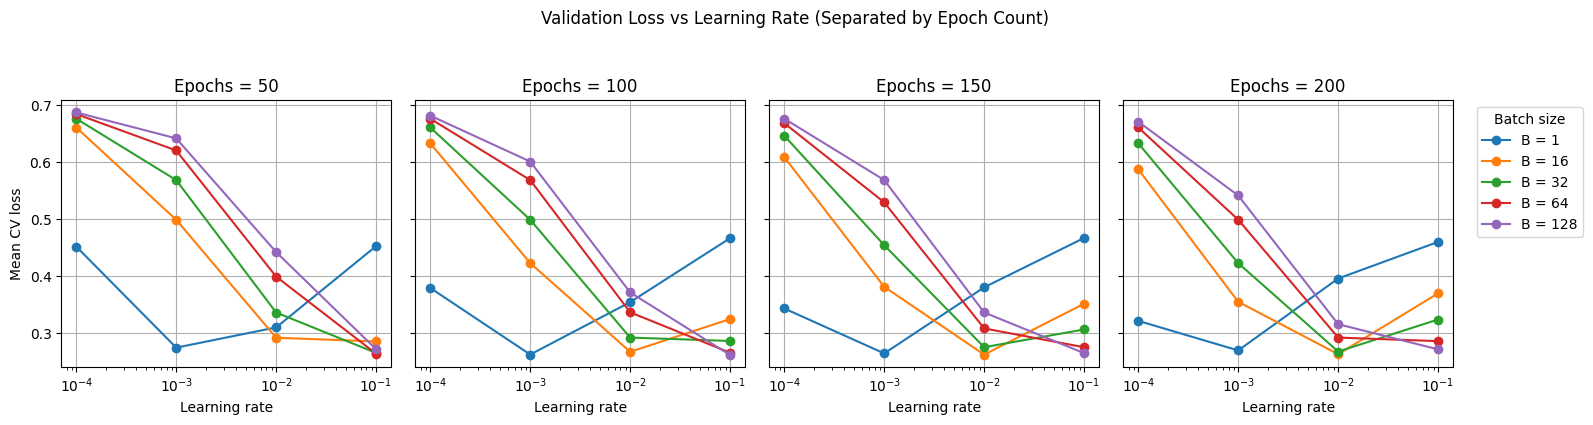

In [ ]:
epoch_values = sorted(cv_df["epochs"].unique())

fig, axes = plt.subplots(
    1, len(epoch_values),
    figsize=(4 * len(epoch_values), 4),
    sharey=True
)

for ax, ep in zip(axes, epoch_values):
    subset_ep = cv_df[cv_df["epochs"] == ep]

    for B in sorted(subset_ep["batch_size"].unique()):
        subset = (
            subset_ep[subset_ep["batch_size"] == B]
            .sort_values("learning_rate")
            # Sorting is necessary to connect the trend lines in sequential order by learning rate
        )

        ax.plot(
            subset["learning_rate"],
            subset["mean_cv_loss"],
            marker="o",
            label=f"B = {B}"
        )

    ax.set_xscale("log")
    ax.set_xlabel("Learning rate")
    ax.set_title(f"Epochs = {ep}")
    ax.grid(True)

axes[0].set_ylabel("Mean CV loss")

# Put legend outside the rightmost subplot
axes[-1].legend(
    title="Batch size",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.suptitle(
    "Validation Loss vs Learning Rate (Separated by Epoch Count)",
    y=1.05
)

plt.tight_layout()
plt.show()
# This is effectively a 3D graph, displayed as cross sections across the Epoch dimension

**Observations:**

Across all Epochs, 50 -- 200, `B = 1` yields the best mean CV loss with a learning rate of 10^-3.  

Similarly, across most epochs, `B = 16` and `B = 32` minimizes loss when the learning rate is 10^-2.

Larger batch sizes (ex. 64, 128) continue to see reductions to mean CV loss as the learning rate trends from 10^-4 to 10^-1, indicating that perhaps an even greater learning rate would be beneficial to such batch sizes due to their stability.  Because they average more observations, across all epochs, the greater learning rate yielded lower cross-entropy loss.

Notice that between all 4 epoch settings, the overall shape, trend, and ordering of the lines on these graphs is consistent and similar.This indicates that Mean Test Loss is very strongly influenced by the learning rate selected. **The difference in Loss between learning rates 10^-4 and 10^-1 can be as much as 0.4** indicating that *learning rate is one of the most impactful hyperparameter*.

Secondly, the vertical spacing between the curves of different batch sizes us responsible for **a difference in Loss almost as high as 0.4** (ex. see `Epochs = 200` (`B = 1`) vs (`B = 128`)).  This also cements *Batch Size as a hyperparameter that matters significantly*.

**Best Hyperparameter Configuration:** In line with our table results, and incorporating our insights from the above learning rate analysis, the optimal hyperparameter configuration should involve a larger batch size, as this allows for a higher learning rate and yet low cross-entropy loss, it also leads to a lower-variance (stabler) model--meaning it is less likely to be confident + incorrect in binary classification.

Hence, from the table, the **best performing hyperparameter configuration** is with `Batch size = 128`, `Epochs = 100`, and `Learning Rate = 0.1`, yielding accuracy of over 92%, low variance for both loss and accuracy, and the lowest possible `mean loss = 0.2622`.

## Task 3 - Bias–Variance Trade-Off via λ Sweep (With K-Fold CV)

In this section, we analyze the influence of the regularization strenght on the two different generalization errors, bias and variance.

Chosen strenght:
$λ ∈ \{0, 10^{-6}, 10^{-5}, 10^{-4}, 10^{-3}, 10^{-2}, 10^{-1}, 1\}$

In [ ]:
# Task 3 fixed hyperparameters as per instructions
FIXED_LR = 0.1
FIXED_BATCH_SIZE = 16
FIXED_EPOCHS = 200

# Define the grid for lambda
lambdas = [0, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1]
task3_results = []

# K-fold CV
for lam in lambdas:
    f_train_losses, f_val_losses, f_train_accs, f_val_accs, weights_norms = [], [], [], [], []

    for train_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train[train_idx], X_train[val_idx]
        y_tr, y_val = y_train[train_idx], y_train[val_idx]

        # Train
        w, b, _, _ = train_logistic_regression_sgd(X_tr, y_tr, FIXED_LR, FIXED_BATCH_SIZE, FIXED_EPOCHS, lam)

        # Evaluate train folds
        y_h_tr = sigmoid(X_tr @ w + b)
        f_train_losses.append(binary_cross_entropy(y_tr, y_h_tr))
        f_train_accs.append(accuracy(y_tr, y_h_tr))

        # Evaluate validation fold
        y_h_val = sigmoid(X_val @ w + b)
        f_val_losses.append(binary_cross_entropy(y_val, y_h_val))
        f_val_accs.append(accuracy(y_val, y_h_val))
        weights_norms.append(np.linalg.norm(w))

    task3_results.append({
        "lambda": lam,
        "train_loss": np.mean(f_train_losses),
        "std_train_loss": np.std(f_train_losses),
        "val_loss": np.mean(f_val_losses),
        "std_val_loss": np.std(f_val_losses),
        "train_acc": np.mean(f_train_accs),
        "std_train_acc": np.std(f_train_accs),
        "val_acc": np.mean(f_val_accs),
        "std_val_acc": np.std(f_val_accs),
        "weights_norms": np.mean(weights_norms)
    })

task3_df = pd.DataFrame(task3_results)

<>:20: SyntaxWarning: invalid escape sequence '\l'
<>:29: SyntaxWarning: invalid escape sequence '\l'
<>:50: SyntaxWarning: invalid escape sequence '\l'
<>:59: SyntaxWarning: invalid escape sequence '\l'
<>:20: SyntaxWarning: invalid escape sequence '\l'
<>:29: SyntaxWarning: invalid escape sequence '\l'
<>:50: SyntaxWarning: invalid escape sequence '\l'
<>:59: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipython-input-1001940781.py:20: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_xlabel('Regularization Strength ($\lambda$)')
/tmp/ipython-input-1001940781.py:29: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_title('Loss Stability vs. $\lambda$')
/tmp/ipython-input-1001940781.py:50: SyntaxWarning: invalid escape sequence '\l'
  ax2.set_xlabel('Regularization Strength ($\lambda$)')
/tmp/ipython-input-1001940781.py:59: SyntaxWarning: invalid escape sequence '\l'
  ax2.set_title('Accuracy Stability vs. $\lambda$')


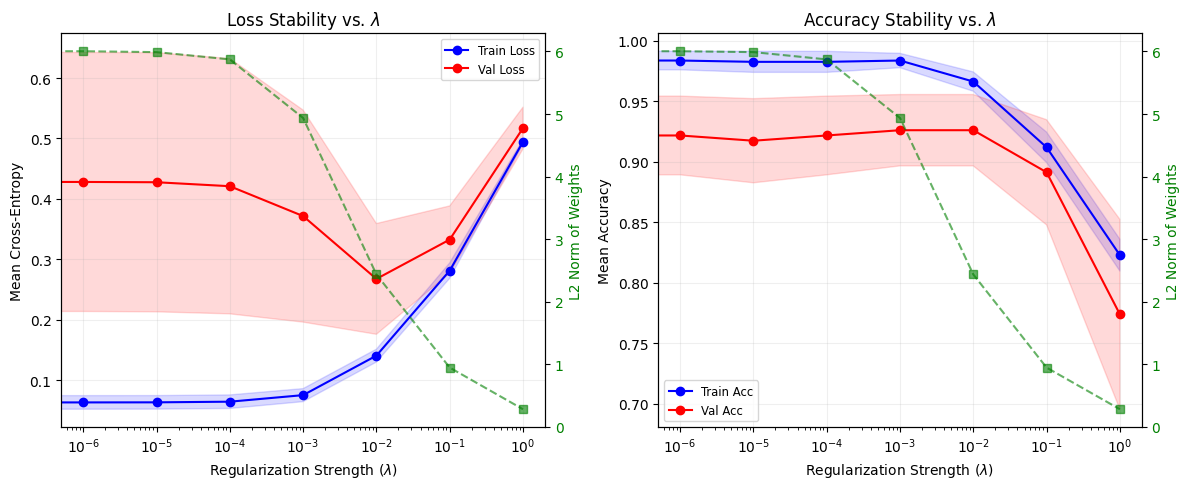

In [ ]:
plt.figure(figsize=(12, 5))

# Plot 1: Cross-Entropy with Error Bands
ax1 = plt.subplot(1, 2, 1)
# Train Loss
ax1.plot(task3_df['lambda'], task3_df['train_loss'], 'o-', label='Train Loss', color='blue')
ax1.fill_between(task3_df['lambda'],
                 task3_df['train_loss'] - task3_df['std_train_loss'],
                 task3_df['train_loss'] + task3_df['std_train_loss'],
                 color='blue', alpha=0.15)

# Val Loss
ax1.plot(task3_df['lambda'], task3_df['val_loss'], 'o-', label='Val Loss', color='red')
ax1.fill_between(task3_df['lambda'],
                 task3_df['val_loss'] - task3_df['std_val_loss'],
                 task3_df['val_loss'] + task3_df['std_val_loss'],
                 color='red', alpha=0.15)

ax1.set_xscale('log')
ax1.set_xlabel('Regularization Strength ($\lambda$)')
ax1.set_ylabel('Mean Cross-Entropy')

# Secondary Axis for Weights
ax1_twin = ax1.twinx()
ax1_twin.plot(task3_df['lambda'], task3_df['weights_norms'], 's--', label='Weights norm', color='green', alpha=0.6)
ax1_twin.set_ylabel('L2 Norm of Weights', color='green')
ax1_twin.tick_params(axis='y', labelcolor='green')

ax1.set_title('Loss Stability vs. $\lambda$')
ax1.legend(loc='upper right', fontsize='small')
ax1.grid(True, alpha=0.2)

# Plot 2: Accuracy with Error Bands
ax2 = plt.subplot(1, 2, 2)
# Train Acc
ax2.plot(task3_df['lambda'], task3_df['train_acc'], 'o-', label='Train Acc', color='blue')
ax2.fill_between(task3_df['lambda'],
                 task3_df['train_acc'] - task3_df['std_train_acc'],
                 task3_df['train_acc'] + task3_df['std_train_acc'],
                 color='blue', alpha=0.15)

# Val Acc
ax2.plot(task3_df['lambda'], task3_df['val_acc'], 'o-', label='Val Acc', color='red')
ax2.fill_between(task3_df['lambda'],
                 task3_df['val_acc'] - task3_df['std_val_acc'],
                 task3_df['val_acc'] + task3_df['std_val_acc'],
                 color='red', alpha=0.15)

ax2.set_xscale('log')
ax2.set_xlabel('Regularization Strength ($\lambda$)')
ax2.set_ylabel('Mean Accuracy')

# Secondary Axis for Weights
ax2_twin = ax2.twinx()
ax2_twin.plot(task3_df['lambda'], task3_df['weights_norms'], 's--', label='Weights norm', color='green', alpha=0.6)
ax2_twin.set_ylabel('L2 Norm of Weights', color='green')
ax2_twin.tick_params(axis='y', labelcolor='green')

ax2.set_title('Accuracy Stability vs. $\lambda$')
ax2.legend(loc='lower left', fontsize='small')
ax2.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

The graph above illustrates the two primary types of generalization error. On the left (small $\lambda$), we observe a significant gap between the training and validation loss. Given that our training set is intentionally small ($N = 230$) relative to the number of features (57), the model is highly susceptible to overfitting, characterized by high variance. In this regime, the model "memorizes" noise in the training data that does not generalize to the validation folds.

Conversely, as the regularization strength increases, the penalty forces the model weights toward zero. This restricts the model's capacity to the point where it can no longer capture the underlying patterns in the data, resulting in poor accuracy and high loss across both training and validation sets. This is the underfitting regime, characterized by high bias.

The optimal balance is found at the "sweet spot" of the validation curve (the U-shape minimum). To minimize generalization error, the graph suggests $\lambda = 10^{-2}$, where the validation accuracy is maximized and the validation loss is at its lowest point before the model begins to underfit.

The green dashed line illustrates the weight decay as $\lambda$ increases.

The shaded region is the $\pm 1$ standard deviation accross the K folds. Regularization not only prevents overfitting but can also make the model's performance more stable across different data folds (reducing Variance in the Bias-Variance tradeoff).


In [ ]:
# Find best lambda based on validation loss
best_lam = task3_df.loc[task3_df['val_loss'].idxmin(), 'lambda']
print(f"Optimal Lambda Selected: {best_lam}")

# Retrain on the full training set using the best lambda
w_final, b_final, _, _ = train_logistic_regression_sgd(X_train, y_train, FIXED_LR, FIXED_BATCH_SIZE, FIXED_EPOCHS, best_lam)

# Final Evaluation on the Test Set
y_hat_test = sigmoid(X_test @ w_final + b_final)
test_loss = binary_cross_entropy(y_test, y_hat_test)
test_acc = accuracy(y_test, y_hat_test)

print(f"\nFinal Test Set Results:")
print(f"Cross-Entropy Loss: {test_loss:.4f}")
print(f"Accuracy: {test_acc:.4f}")

Optimal Lambda Selected: 0.01

Final Test Set Results:
Cross-Entropy Loss: 0.4837
Accuracy: 0.8691


## Task 4 - L1-Regularized Logistic Regression and the Regularization Path (Using scikit-learn)

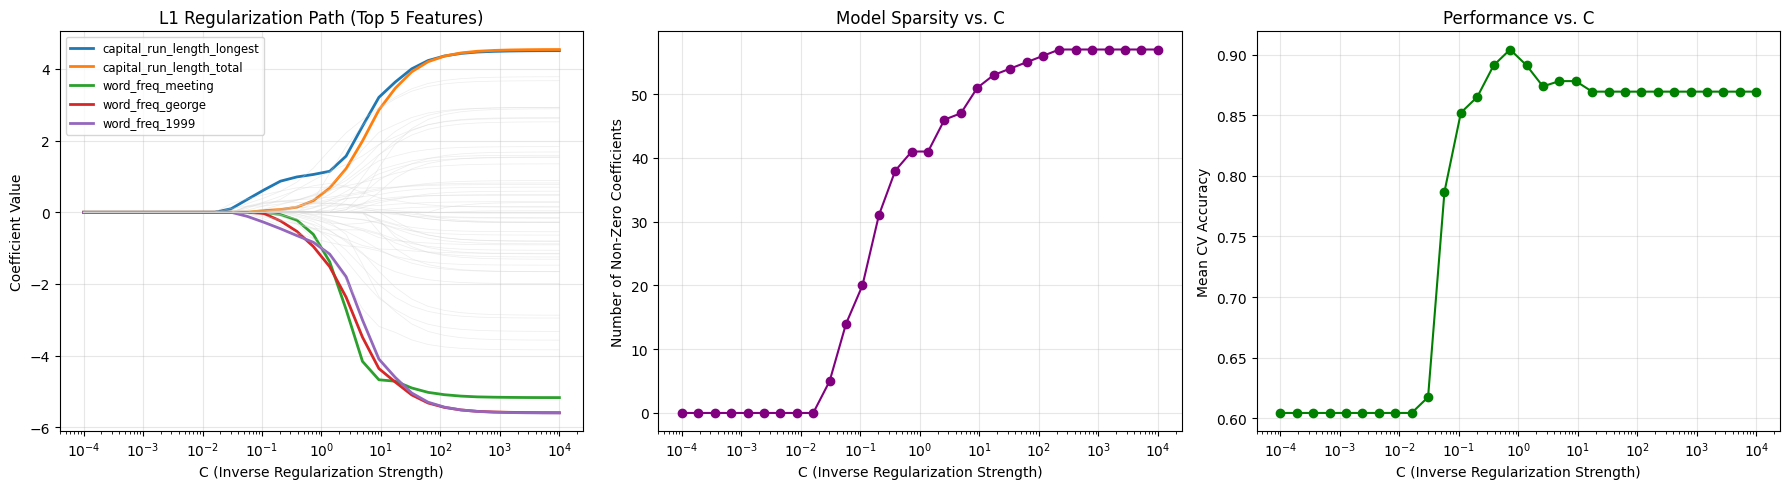

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

# Define the grid for C (Inverse of regularization strength)
Cs = np.logspace(-4, 4, 30)

coefs = []
sparsities = []
cv_accuracies = []

for C in Cs:
    # Initialize L1 Logistic Regression
    model = LogisticRegression(penalty='l1', C=C, solver='saga',
                               random_state=RANDOM_SEED, max_iter=7500,
                               warm_start=True)

    model.fit(X_train, y_train)

    # Store coefficients and sparsity (number of non-zero weights)
    weights = model.coef_[0]
    coefs.append(weights)
    sparsities.append(np.sum(weights != 0))

    # Run K-fold CV to get performance vs C
    scores = cross_val_score(model, X_train, y_train, cv=K, scoring='accuracy')
    cv_accuracies.append(np.mean(scores))

coefs = np.array(coefs)

TOP_K = 5
# Find the absolute values of the coefficients at the weakest regularization (largest C, which is index -1)
final_magnitudes = np.abs(coefs[-1, :])
top_k_indices = np.argsort(final_magnitudes)[-TOP_K:]

# Filter the coefficients and get their corresponding names
top_k_coefs = coefs[:, top_k_indices]
top_k_names = [feature_names[i] for i in top_k_indices]

# Plotting the Results
plt.figure(figsize=(18, 5))

# Plot 1: The Regularization Path
plt.subplot(1, 3, 1)
# Plot the Top K features with labels
for i in range(TOP_K):
    plt.plot(Cs, top_k_coefs[:, i], label=top_k_names[i], linewidth=2)

# Plot the remaining features in light gray so they fade into the background
remaining_indices = [i for i in range(coefs.shape[1]) if i not in top_k_indices]
for i in remaining_indices:
    plt.plot(Cs, coefs[:, i], color='lightgray', alpha=0.4, linewidth=0.5)

plt.xscale('log')
plt.xlabel('C (Inverse Regularization Strength)')
plt.ylabel('Coefficient Value')
plt.title(f'L1 Regularization Path (Top {TOP_K} Features)')
plt.legend(loc='upper left', fontsize='small')
plt.grid(True, alpha=0.3)

# Plot 2: Sparsity Plot
plt.subplot(1, 3, 2)
plt.plot(Cs, sparsities, 'o-', color='purple')
plt.xscale('log')
plt.xlabel('C (Inverse Regularization Strength)')
plt.ylabel('Number of Non-Zero Coefficients')
plt.title('Model Sparsity vs. C')
plt.grid(True, alpha=0.3)

# Plot 3: CV Performance
plt.subplot(1, 3, 3)
plt.plot(Cs, cv_accuracies, 'o-', color='green')
plt.xscale('log')
plt.xlabel('C (Inverse Regularization Strength)')
plt.ylabel('Mean CV Accuracy')
plt.title('Performance vs. C')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

We observe that around $C = 10^{-2}$ (strong regularization), the model is highly sparse, with all feature coefficients reduced to zero. Conversely, as we approach $C = 10^{2}$ (weak regularization), the penalty becomes negligible, and all features are retained in the model. Looking at the performance plot, the optimal regularization strength lies in the middle, around $C = 10^{0}$. At this "sweet spot", the L1 penalty effectively performs feature selection ruling out uninformative features while retaining the core predictive signals of the data, which yields the highest accuracy on the validation set.

Isolating the top five features by absolute magnitude reveals clear patterns in the data. As expected, the length and total frequency of consecutive capital letters strongly indicate spam. Conversely, strong indicators of legitimate emails include common workplace terms like 'meeting', the dataset's creation year ('1999'), and the first name of the dataset's author ('George').